<a href="https://colab.research.google.com/github/swapneelkishore8-lab/House-price-EDA/blob/main/House_Price_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv('/content/train.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (1460, 81)


In [5]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]

missing_percentage = missing_percentage.sort_values(ascending=False)

print(missing_percentage)

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64


In [9]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Ordinal columns
ordinal_cols = ['OverallQual', 'ExterQual', 'KitchenQual']

print("Total Numerical Columns:", len(numeric_cols))
print("Total Categorical Columns:", len(categorical_cols))
print("Ordinal Columns:", ordinal_cols)

Total Numerical Columns: 38
Total Categorical Columns: 43
Ordinal Columns: ['OverallQual', 'ExterQual', 'KitchenQual']


In [10]:
ordinal_map = ['Po', 'Fa', 'TA', 'Gd', 'Ex']

for col in ['ExterQual', 'KitchenQual']:
    df[col] = pd.Categorical(
        df[col],
        categories=ordinal_map,
        ordered=True
    )

print("Ordinal variables converted successfully!")

Ordinal variables converted successfully!


In [11]:
summary = []

for col in df.columns:

    if col in ordinal_cols:
        var_type = "Ordinal"

    elif col in numeric_cols:
        var_type = "Numerical"

    else:
        var_type = "Categorical"

    unique_values = df[col].dropna().unique()[:5]

    summary.append({
        'Column Name': col,
        'Type': var_type,
        'Unique Values': df[col].nunique(),
        'Example Values': list(unique_values)
    })

summary_df = pd.DataFrame(summary)

summary_df

,Column Name,Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


In [12]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [13]:
columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:

    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    print("IQR:", Q3 - Q1)
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurtosis())


Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [14]:
for col in ['Neighborhood', 'HouseStyle']:
    print("\nValue counts for", col)
    print(df[col].value_counts())
    print("Mode:", df[col].mode()[0])


Value counts for Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Mode: NAmes

Value counts for HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Mode: 1Story


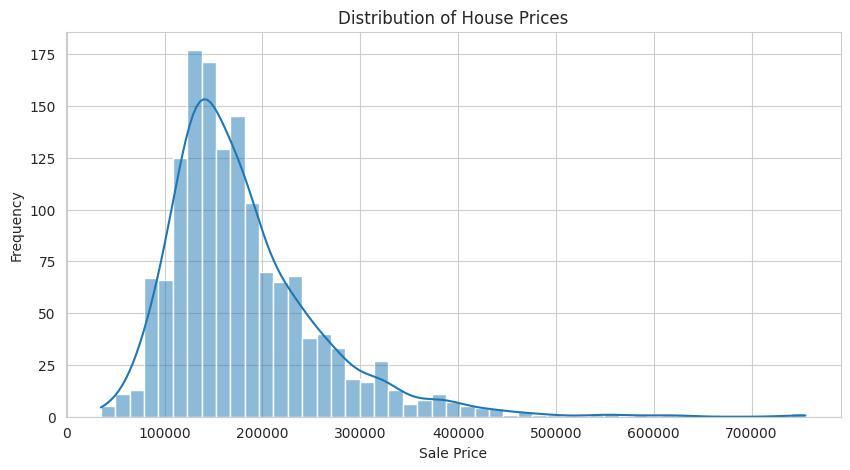

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(df['SalePrice'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

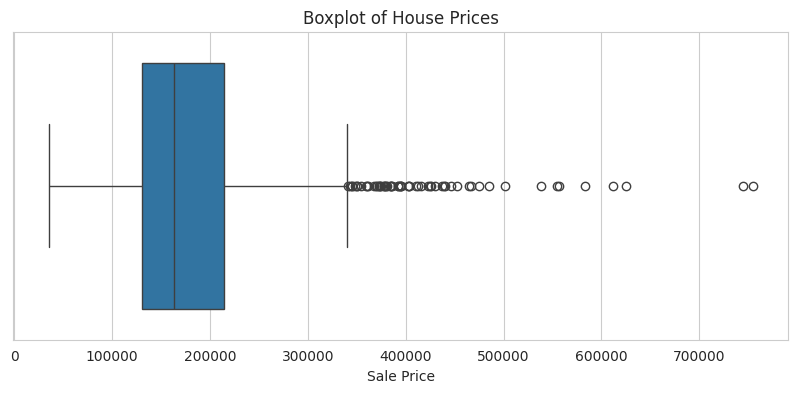

In [16]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['SalePrice'])

plt.title('Boxplot of House Prices')
plt.xlabel('Sale Price')

plt.show()

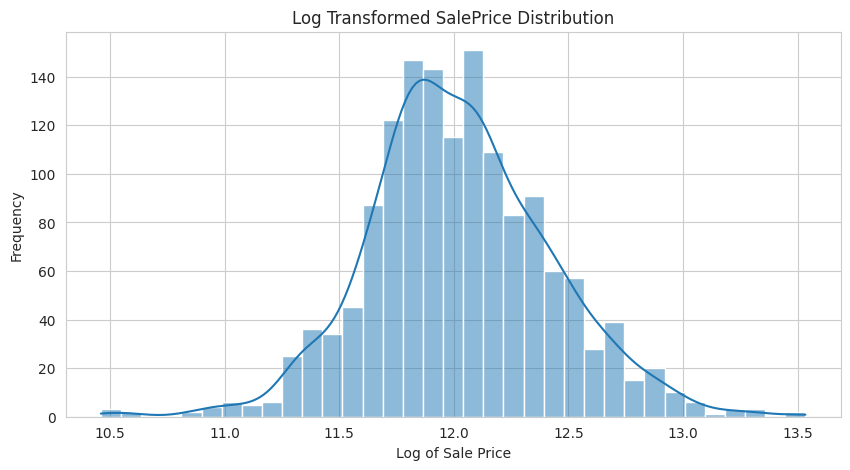

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(df['SalePrice']), kde=True)

plt.title('Log Transformed SalePrice Distribution')
plt.xlabel('Log of Sale Price')
plt.ylabel('Frequency')

plt.show()

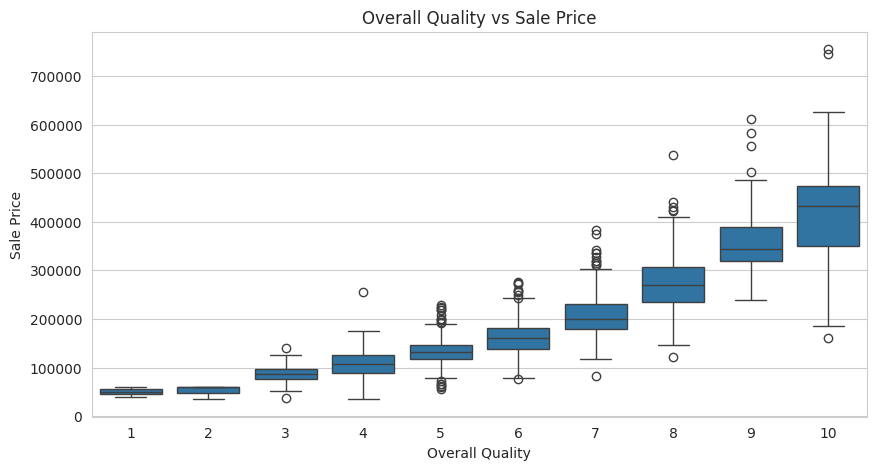

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(x='OverallQual', y='SalePrice', data=df)

plt.title('Overall Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

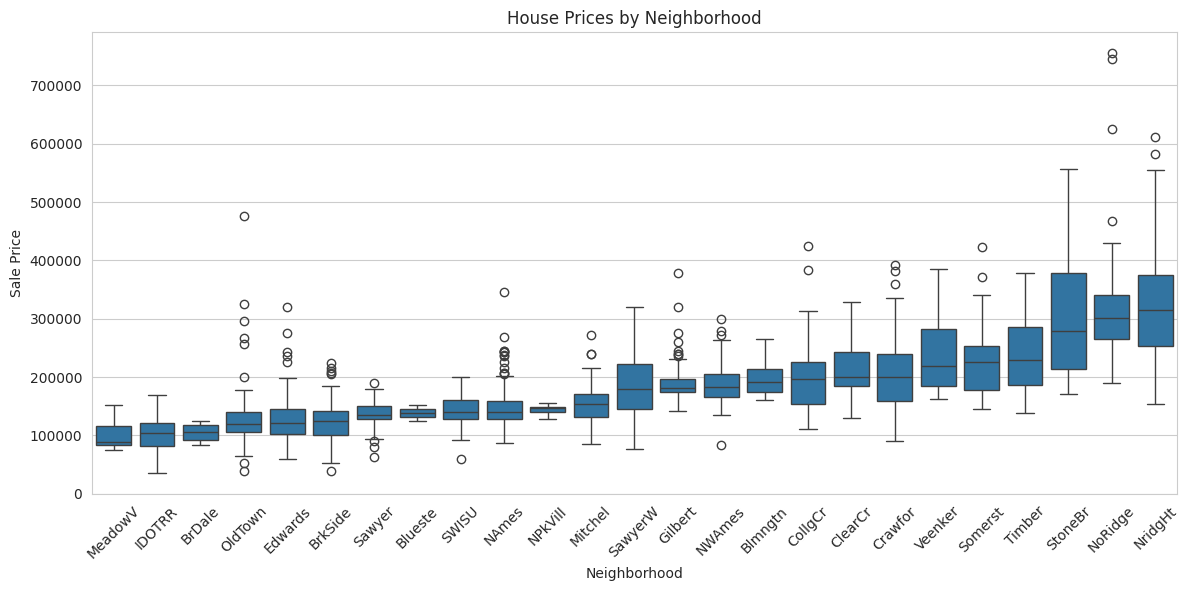

In [19]:
plt.figure(figsize=(14, 6))

neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index

sns.boxplot(x='Neighborhood', y='SalePrice', data=df, order=neighborhood_order)

plt.title('House Prices by Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('Sale Price')
plt.xticks(rotation=45)

plt.show()

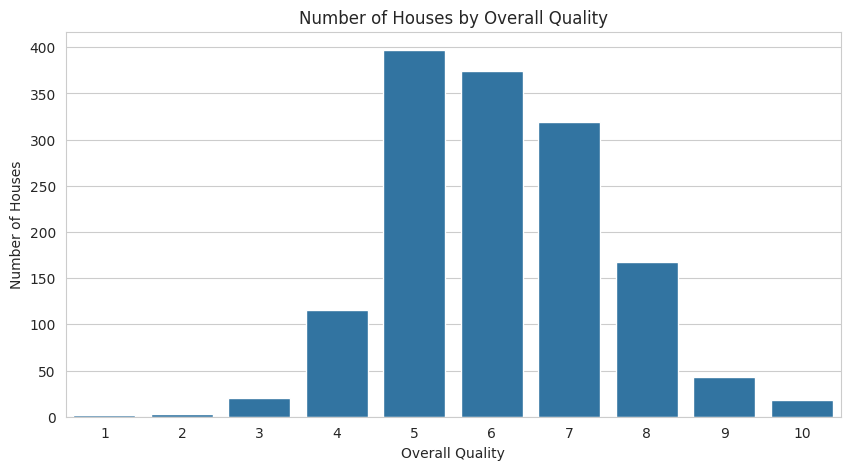

In [20]:
plt.figure(figsize=(10, 5))

sns.countplot(x='OverallQual', data=df)

plt.title('Number of Houses by Overall Quality')
plt.xlabel('Overall Quality')
plt.ylabel('Number of Houses')

plt.show()

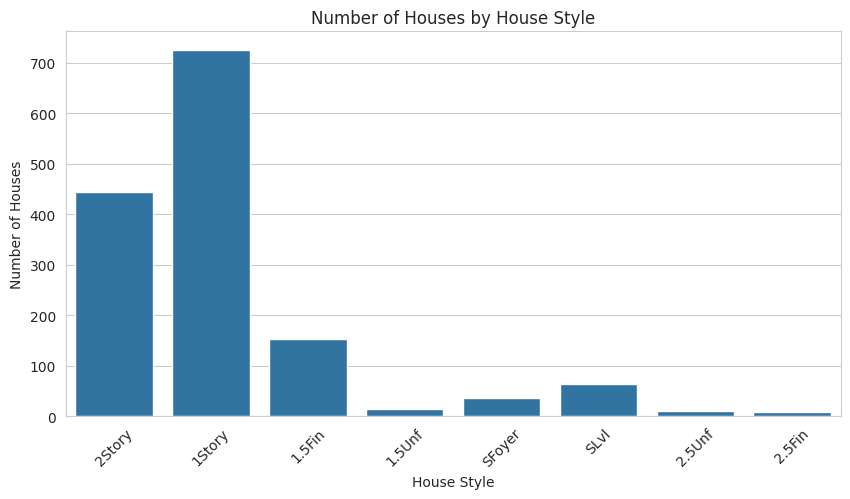

In [21]:
plt.figure(figsize=(10, 5))

sns.countplot(x='HouseStyle', data=df)

plt.title('Number of Houses by House Style')
plt.xlabel('House Style')
plt.ylabel('Number of Houses')
plt.xticks(rotation=45)

plt.show()

In [22]:
correlation_matrix = df.corr(numeric_only=True)

correlation_matrix

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


In [23]:
saleprice_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)

print("Top 10 Features Positively Correlated with SalePrice:")
print(saleprice_corr.head(10))

Top 10 Features Positively Correlated with SalePrice:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


In [24]:
print("Top 10 Negatively Correlated Features:")
print(saleprice_corr.sort_values().head(10))

Top 10 Negatively Correlated Features:
KitchenAbvGr    -0.135907
EnclosedPorch   -0.128578
MSSubClass      -0.084284
OverallCond     -0.077856
YrSold          -0.028923
LowQualFinSF    -0.025606
Id              -0.021917
MiscVal         -0.021190
BsmtHalfBath    -0.016844
BsmtFinSF2      -0.011378
Name: SalePrice, dtype: float64


In [25]:
covariance_matrix = df.cov(numeric_only=True)

covariance_matrix

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.566468e+03,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07


In [26]:
top3_features = (
    correlation_matrix['SalePrice']
    .drop('SalePrice')
    .abs()
    .sort_values(ascending=False)
    .head(3)
    .index
)

for feature in top3_features:
    print("\nFeature:", feature)
    print("Covariance with SalePrice:", covariance_matrix.loc[feature, 'SalePrice'])
    print("Correlation with SalePrice:", correlation_matrix.loc[feature, 'SalePrice'])


Feature: OverallQual
Covariance with SalePrice: 86904.12583679946
Correlation with SalePrice: 0.7909816005838053

Feature: GrLivArea
Covariance with SalePrice: 29581866.743236575
Correlation with SalePrice: 0.7086244776126515

Feature: GarageCars
Covariance with SalePrice: 38020.18135897172
Correlation with SalePrice: 0.6404091972583519


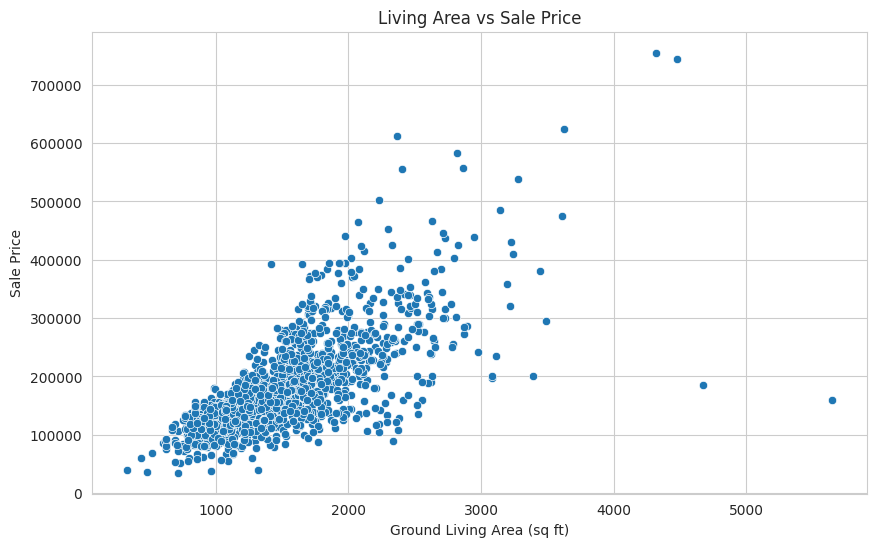

In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)

plt.title('Living Area vs Sale Price')
plt.xlabel('Ground Living Area (sq ft)')
plt.ylabel('Sale Price')

plt.show()

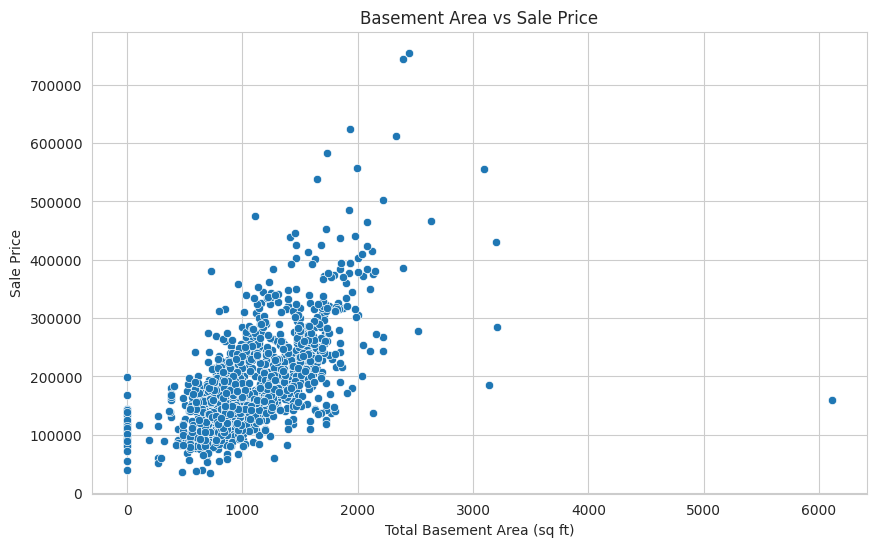

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)

plt.title('Basement Area vs Sale Price')
plt.xlabel('Total Basement Area (sq ft)')
plt.ylabel('Sale Price')

plt.show()

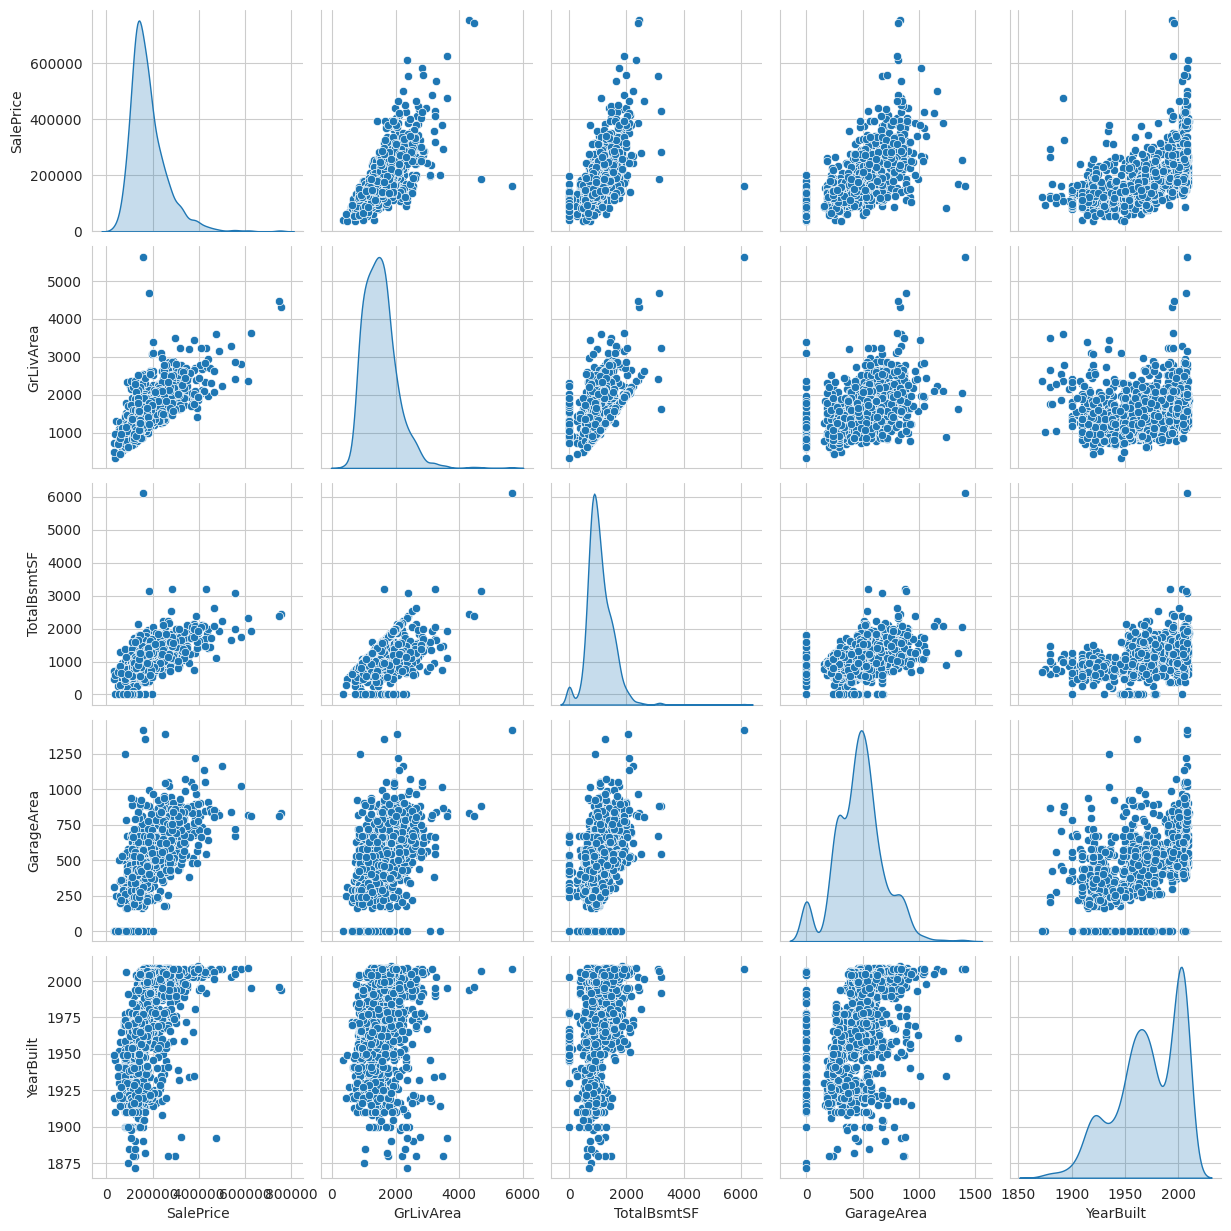

In [29]:
selected = ['SalePrice', 'GrLivArea', 'TotalBsmtSF',
            'GarageArea', 'YearBuilt']

sns.pairplot(df[selected], diag_kind='kde')

plt.show()

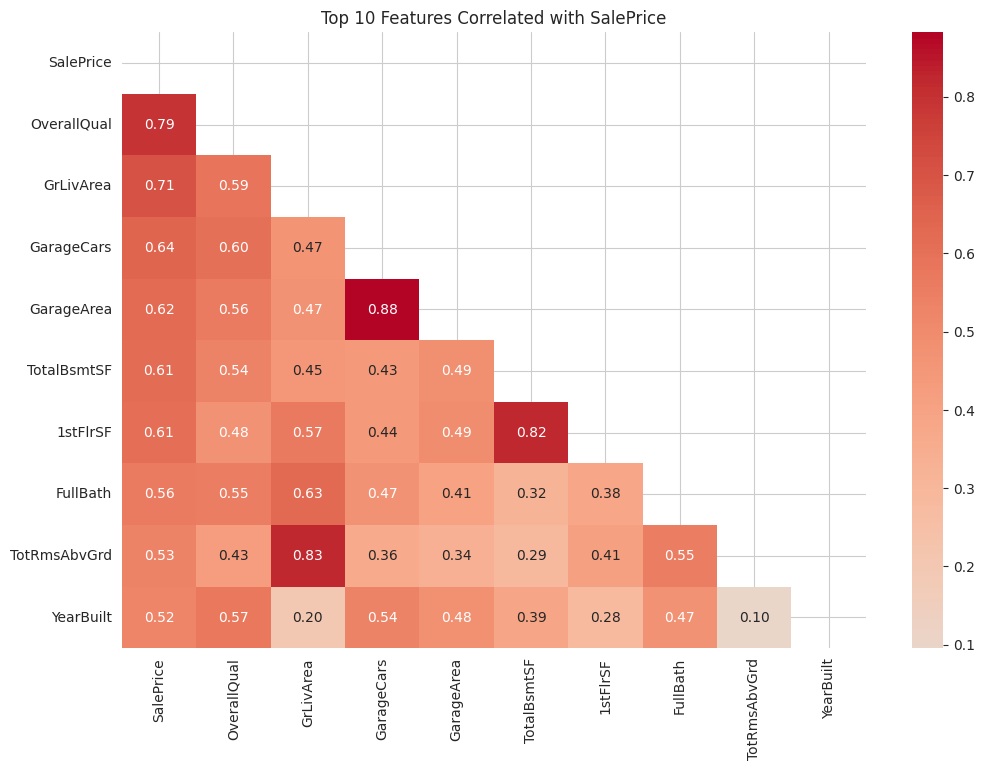

In [30]:
top10 = correlation_matrix['SalePrice'].abs().sort_values(
    ascending=False
).head(10).index

corr_top = df[top10].corr()

mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_top,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    mask=mask
)

plt.title('Top 10 Features Correlated with SalePrice')
plt.show()

In [31]:
def iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return df[(series < lower) | (series > upper)]


def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()

    return df[abs(z) > threshold]


print("Outlier functions created successfully!")

Outlier functions created successfully!


In [32]:
for col in ['GrLivArea', 'SalePrice']:

    iqr_result = iqr_outliers(df[col])
    zscore_result = zscore_outliers(df[col])

    print("\nColumn:", col)
    print("IQR Outliers:", len(iqr_result))
    print("Z-Score Outliers:", len(zscore_result))

    overlap = set(iqr_result.index) & set(zscore_result.index)

    print("Common Outliers:", len(overlap))


Column: GrLivArea
IQR Outliers: 31
Z-Score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-Score Outliers: 22
Common Outliers: 22


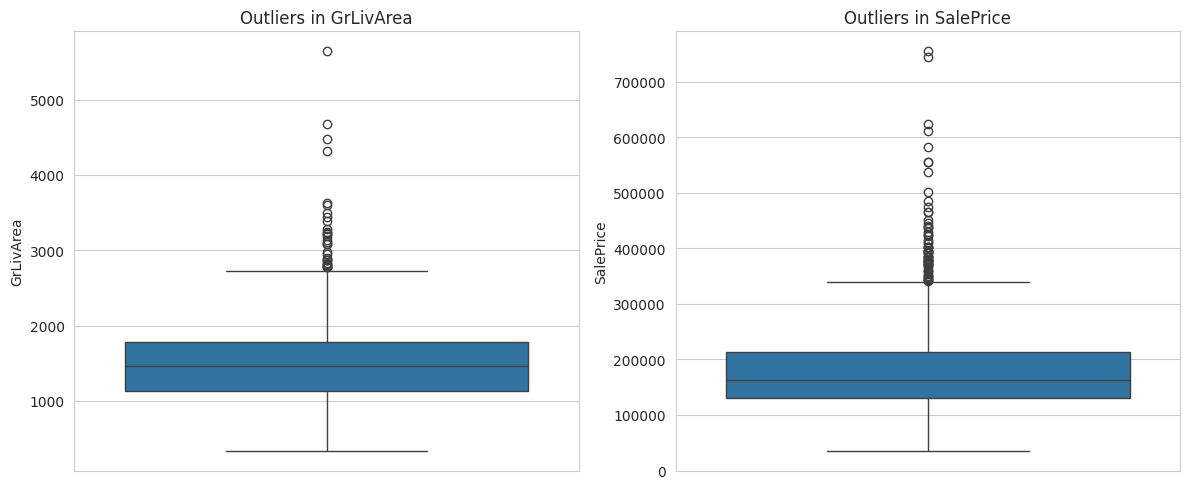

In [33]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['GrLivArea'])
plt.title('Outliers in GrLivArea')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['SalePrice'])
plt.title('Outliers in SalePrice')

plt.tight_layout()
plt.show()

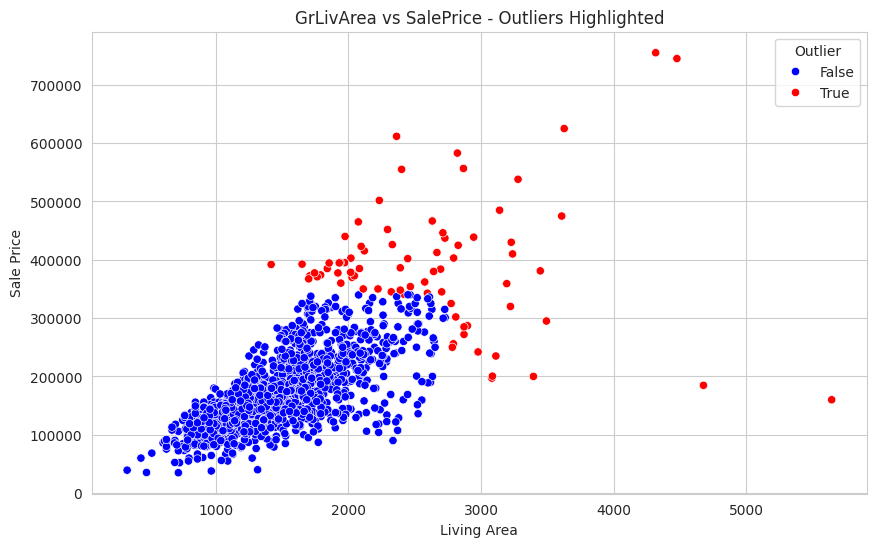

In [34]:
iqr_area = iqr_outliers(df['GrLivArea'])
iqr_price = iqr_outliers(df['SalePrice'])

outlier_indices = set(iqr_area.index) | set(iqr_price.index)

df['Outlier'] = df.index.isin(outlier_indices)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    hue='Outlier',
    palette={True: 'red', False: 'blue'}
)

plt.title('GrLivArea vs SalePrice - Outliers Highlighted')
plt.xlabel('Living Area')
plt.ylabel('Sale Price')

plt.show()

In [35]:
dup_count = df.duplicated().sum()

print("Number of Duplicate Rows:", dup_count)

if dup_count > 0:
    df = df.drop_duplicates()
    print("New Dataset Shape:", df.shape)
else:
    print("No duplicate rows found!")

Number of Duplicate Rows: 0
No duplicate rows found!


In [36]:
for col in categorical_cols:
    values = df[col].dropna().astype(str)

    extra_spaces = values.str.contains(r'^\s|\s$', regex=True).sum()
    lowercase_values = values.str.islower().sum()

    if extra_spaces > 0 or lowercase_values > 0:
        print("\nColumn:", col)
        print("Values with extra spaces:", extra_spaces)
        print("Lowercase values:", lowercase_values)

print("\nCategorical consistency check completed!")


Categorical consistency check completed!


In [37]:
categorical_missing_cols = [
    'PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType'
]

for col in categorical_missing_cols:
    df[col] = df[col].fillna('None')

print("Categorical missing values handled!")

Categorical missing values handled!


In [38]:
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("Numerical missing values handled!")

Numerical missing values handled!


In [39]:
remaining_missing = df.isnull().sum()

print("Columns with remaining missing values:")
print(remaining_missing[remaining_missing > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Columns with remaining missing values:
MasVnrType       872
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
GarageFinish      81
GarageQual        81
GarageCond        81
MiscFeature     1406
dtype: int64

Total Missing Values: 2709


In [41]:
missing_as_none = [
    'MasVnrType',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'MiscFeature'
]

for col in missing_as_none:
    df[col] = df[col].fillna('None')

# Electrical has one missing value, fill it with mode
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

print("Remaining categorical missing values handled!")

Remaining categorical missing values handled!


In [42]:
remaining_missing = df.isnull().sum()

print("Columns with remaining missing values:")
print(remaining_missing[remaining_missing > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Columns with remaining missing values:
Series([], dtype: int64)

Total Missing Values: 0


In [43]:
print("Houses built after sale year:",
      (df['YearBuilt'] > df['YrSold']).sum())

area_columns = ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'LotArea']

for col in area_columns:
    print(f"Negative values in {col}:",
          (df[col] < 0).sum())

Houses built after sale year: 0
Negative values in GrLivArea: 0
Negative values in TotalBsmtSF: 0
Negative values in GarageArea: 0
Negative values in LotArea: 0


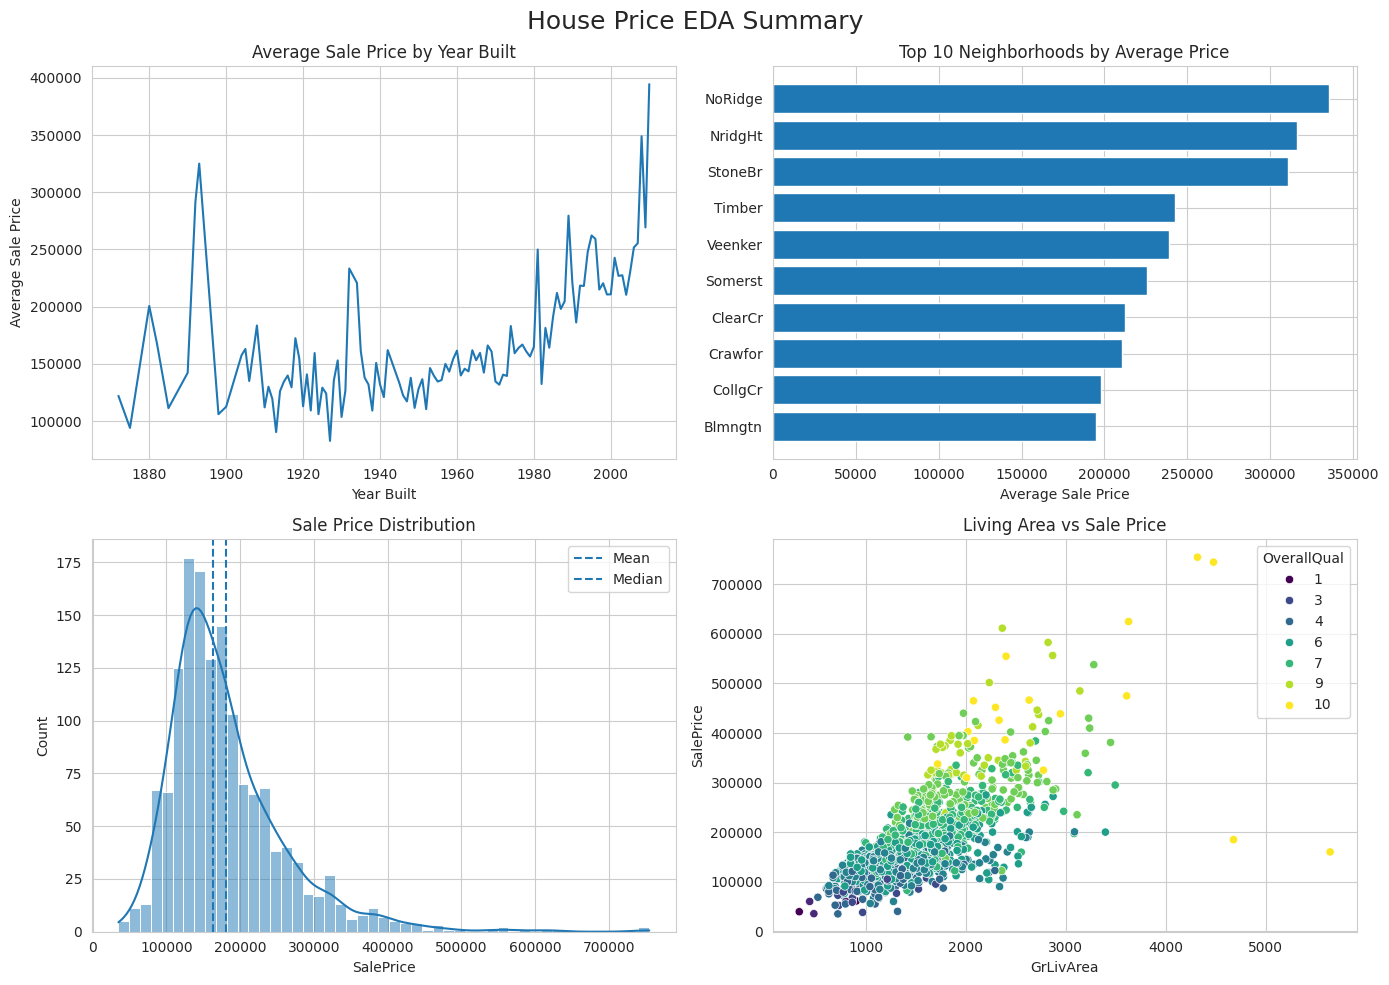

Final EDA Dashboard created successfully!


In [44]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Graph 1: Average Sale Price by Year Built
year_price = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(year_price.index, year_price.values)

axes[0, 0].set_title('Average Sale Price by Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Sale Price')


# Graph 2: Top 10 Neighborhoods by Average Price
neighborhood_price = (
    df.groupby('Neighborhood')['SalePrice']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

axes[0, 1].barh(
    neighborhood_price.index,
    neighborhood_price.values
)

axes[0, 1].set_title('Top 10 Neighborhoods by Average Price')
axes[0, 1].set_xlabel('Average Sale Price')
axes[0, 1].invert_yaxis()


# Graph 3: SalePrice Distribution
sns.histplot(
    df['SalePrice'],
    kde=True,
    ax=axes[1, 0]
)

axes[1, 0].axvline(
    df['SalePrice'].mean(),
    linestyle='--',
    label='Mean'
)

axes[1, 0].axvline(
    df['SalePrice'].median(),
    linestyle='--',
    label='Median'
)

axes[1, 0].set_title('Sale Price Distribution')
axes[1, 0].legend()


# Graph 4: Living Area vs Sale Price
sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    hue='OverallQual',
    palette='viridis',
    ax=axes[1, 1]
)

axes[1, 1].set_title('Living Area vs Sale Price')


# Final Dashboard
fig.suptitle('House Price EDA Summary', fontsize=18)

plt.tight_layout()

plt.savefig('eda_dashboard.png', dpi=300, bbox_inches='tight')

plt.show()

print("Final EDA Dashboard created successfully!")

Final Conclusions and Observations
The dataset contains 1,460 rows and 81 columns.
Missing values were identified and handled using suitable methods.
SalePrice distribution was right-skewed, and log transformation helped make the distribution more balanced.
OverallQual and GrLivArea show strong positive correlations with SalePrice.
GarageCars and GarageArea are strongly correlated with each other.
House prices vary across different neighborhoods.
Outlier detection was performed using IQR and Z-score methods.
Visualizations helped understand relationships between house features and selling prices.
Final Conclusion
Exploratory Data Analysis helped us understand the Ames Housing Dataset, identify missing values and outliers, study correlations, and visualize the factors associated with house prices.

In [45]:
plt.savefig('/content/eda_dashboard.png', dpi=300, bbox_inches='tight')

print("Dashboard saved successfully!")

Dashboard saved successfully!


<Figure size 640x480 with 0 Axes>